# Exploración de Silver raw

Objetivo: dar los datos para elegir variables, sin elegirlas todavía.

1. **¿Qué hay?** Cobertura de cada variable por ciclo.
2. **¿Es fiable y comparable?** Distribuciones, extremos y saltos entre ciclos (cambios de método).
3. **¿Aporta algo?** Correlaciones entre candidatas y asociación con mortalidad ajustada por edad y sexo (orientativa).
4. **¿Cómo es la población?** Para el documento de la entrega.

Lee `data/02_silver/silver_raw.parquet` (generado por `src.main`). No importa nada de `src/`.

In [1]:
# Imports
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter

# Paths
RAW = Path("..") / "data" / "02_silver" / "silver_raw.parquet"

# Display
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

raw = pd.read_parquet(RAW)
raw.shape

(54809, 993)

## Variables candidatas

Criterio acordado:
- **Rutina**: lo que sale en una analítica de rutina española.
- **Frecuente**: no es de rutina, pero se pide a menudo.
- **Medidas**: lo que el usuario sabe sin pensar (peso, talla) o puede saber (tensión, cintura).
- **Cuestionario**: máximo ~10 preguntas rápidas de botones.
- **Difícil**: el usuario casi nunca lo sabe (VO2 max, DXA). Se mira por completitud.

Nombres NHANES ya armonizados en Silver raw.

In [2]:
# Candidates: NHANES name → (group, readable name)
CANDIDATES = {
    # Demographics
    "RIDAGEYR": ("demographics", "age"),
    "RIAGENDR": ("demographics", "sex (1 male, 2 female)"),

    # Routine: blood count
    "LBXWBCSI": ("routine", "leukocytes (10^3/uL)"),
    "LBXRBCSI": ("routine", "erythrocytes (10^6/uL)"),
    "LBXHGB":   ("routine", "hemoglobin (g/dL)"),
    "LBXHCT":   ("routine", "hematocrit (%)"),
    "LBXMCVSI": ("routine", "MCV (fL)"),
    "LBXMCHSI": ("routine", "MCH (pg)"),
    "LBXMC":    ("routine", "MCHC (g/dL)"),
    "LBXRDW":   ("routine", "RDW (%)"),
    "LBXPLTSI": ("routine", "platelets (10^3/uL)"),
    "LBXMPSI":  ("routine", "MPV (fL)"),
    "LBXNEPCT": ("routine", "neutrophils (%)"),
    "LBXLYPCT": ("routine", "lymphocytes (%)"),
    "LBXMOPCT": ("routine", "monocytes (%)"),
    "LBXEOPCT": ("routine", "eosinophils (%)"),
    "LBXBAPCT": ("routine", "basophils (%)"),
    "LBDNENO":  ("routine", "neutrophils (10^3/uL)"),
    "LBDLYMNO": ("routine", "lymphocytes (10^3/uL)"),
    "LBDMONO":  ("routine", "monocytes (10^3/uL)"),
    "LBDEONO":  ("routine", "eosinophils (10^3/uL)"),
    "LBDBANO":  ("routine", "basophils (10^3/uL)"),

    # Routine: biochemistry
    "LBXSGL":   ("routine", "glucose, serum, any fasting (mg/dL)"),
    "LBXGLU":   ("routine", "glucose, plasma, fasting subsample (mg/dL)"),
    "LBXSBU":   ("routine", "BUN (mg/dL), urea = BUN x 2.14"),
    "LBXSCR":   ("routine", "creatinine (mg/dL)"),
    "LBXSUA":   ("routine", "uric acid (mg/dL)"),
    "LBXSCH":   ("routine", "total cholesterol, biochemistry profile (mg/dL)"),
    "LBXTC":    ("routine", "total cholesterol, lipid file (mg/dL)"),
    "LBDHDD":   ("routine", "HDL (mg/dL)"),
    "LBDLDL":   ("routine", "LDL, fasting subsample (mg/dL)"),
    "LBXSTR":   ("routine", "triglycerides, any fasting (mg/dL)"),
    "LBXTR":    ("routine", "triglycerides, fasting subsample (mg/dL)"),
    "LBXSASSI": ("routine", "AST (U/L)"),
    "LBXSATSI": ("routine", "ALT (U/L)"),
    "LBXSGTSI": ("routine", "GGT (U/L)"),
    "LBXSAPSI": ("routine", "alkaline phosphatase (U/L)"),
    "LBXSTB":   ("routine", "total bilirubin (mg/dL)"),
    "LBXSNASI": ("routine", "sodium (mmol/L)"),
    "LBXSKSI":  ("routine", "potassium (mmol/L)"),

    # Frequent
    "LBXGH":    ("frequent", "HbA1c (%)"),
    "LBXSCA":   ("frequent", "calcium (mg/dL)"),
    "LBXSPH":   ("frequent", "phosphorus (mg/dL)"),
    "LBXSTP":   ("frequent", "total protein (g/dL)"),
    "LBXSAL":   ("frequent", "albumin (g/dL)"),
    "LBXSIR":   ("frequent", "iron (ug/dL)"),
    "LBXSLDSI": ("frequent", "LDH (U/L)"),
    "LBXSCK":   ("frequent", "CPK (U/L)"),
    "LBXSCLSI": ("frequent", "chloride (mmol/L)"),
    "LBXCRP":   ("frequent", "CRP, standard (mg/dL), until 2010"),
    "LBXHSCRP": ("frequent", "hs-CRP (mg/L), from 2015"),
    "LBXVIDMS": ("frequent", "25-OH vitamin D (nmol/L)"),
    "LBXIN":    ("frequent", "insulin, fasting subsample (uU/mL)"),
    "URXUMA":   ("frequent", "urine albumin (ug/mL)"),
    "URXUCR":   ("frequent", "urine creatinine (mg/dL)"),

    # Measures
    "BMXWT":    ("measures", "weight (kg)"),
    "BMXHT":    ("measures", "height (cm)"),
    "BMXBMI":   ("measures", "BMI (kg/m2)"),
    "BMXWAIST": ("measures", "waist (cm)"),
    "BPXSY1":   ("measures", "systolic BP, 1st reading (mmHg)"),
    "BPXDI1":   ("measures", "diastolic BP, 1st reading (mmHg)"),

    # Questionnaire
    "SMQ020":   ("questionnaire", "smoked 100+ cigarettes in life"),
    "SMQ040":   ("questionnaire", "smokes now"),
    "ALQ120Q":  ("questionnaire", "alcohol frequency (until 2016)"),
    "ALQ121":   ("questionnaire", "alcohol frequency (2017)"),
    "ALQ130":   ("questionnaire", "alcohol drinks per drinking day"),
    "PAD200":   ("questionnaire", "vigorous activity, past 30 days (until 2006)"),
    "PAD320":   ("questionnaire", "moderate activity, past 30 days (until 2006)"),
    "PAQ650":   ("questionnaire", "vigorous recreational activity (from 2007)"),
    "PAQ665":   ("questionnaire", "moderate recreational activity (from 2007)"),
    "PAD680":   ("questionnaire", "sedentary minutes per day (from 2007)"),
    "DBD900":   ("questionnaire", "fast food meals, past 7 days (from 2007)"),
    "SLD010H":  ("questionnaire", "sleep hours (2005-2014)"),
    "SLD012":   ("questionnaire", "sleep hours (from 2015)"),

    # Hard to know
    "CVDESVO2": ("hard", "estimated VO2 max (ml/kg/min)"),
    "DXDTOPF":  ("hard", "total body fat, DXA (%)"),
}

# Questionnaire codes for refused / don't know (→ missing)
MISSING_CODES = {
    "ALQ130":  [777, 999],
    "PAD680":  [7777, 9999],
    "DBD900":  [5555, 7777, 9999],
    "SLD010H": [77, 99],
}

# Numeric variables for distributions, correlations and mortality
NUMERIC = [v for v, (group, _) in CANDIDATES.items() if group in ("routine", "frequent", "measures", "hard")]
NUMERIC += ["ALQ130", "PAD680", "DBD900", "SLD010H", "SLD012"]

missing_in_raw = [v for v in CANDIDATES if v not in raw.columns]
print(f"{len(CANDIDATES)} candidates, missing in raw: {missing_in_raw}")

76 candidates, missing in raw: []


## 4. Población de estudio

Exclusiones:
- Sin examen físico (solo entrevista): no tienen analítica. **Decidido.**
- Embarazadas: la analítica está alterada por el embarazo. **Decidido.**

In [3]:
examined = raw["RIDSTATR"] == 2
pregnant = raw["RIDEXPRG"] == 1
data = raw[examined & ~pregnant].copy()

for var, codes in MISSING_CODES.items():
    data[var] = data[var].mask(data[var].isin(codes))

print(f"Silver raw: {len(raw)}")
print(f"  - without exam: {(~examined).sum()}")
print(f"  - pregnant: {(examined & pregnant).sum()}")
print(f"Study population: {len(data)} persons, {int(data['MORTSTAT'].sum())} deaths")

Silver raw: 54809
  - without exam: 2253
  - pregnant: 1587
Study population: 50969 persons, 5808 deaths


In [4]:
population = data.groupby("cycle").agg(
    persons=("SEQN", "size"),
    deaths=("MORTSTAT", "sum"),
    women_pct=("RIAGENDR", lambda s: 100 * (s == 2).mean()),
    age_mean=("RIDAGEYR", "mean"),
    follow_up_years=("PERMTH_EXM", lambda s: s.median() / 12),
)
population.loc["total"] = [
    len(data), data["MORTSTAT"].sum(), 100 * (data["RIAGENDR"] == 2).mean(),
    data["RIDAGEYR"].mean(), data["PERMTH_EXM"].median() / 12,
]
population.round(1)

,persons,deaths,women_pct,age_mean,follow_up_years
cycle,,,,,
1999_2000,4368.0,1129.0,50.1,45.1,19.6
2001_2002,4859.0,999.0,48.7,44.1,17.8
2003_2004,4591.0,864.0,48.9,44.7,15.8
2005_2006,4620.0,634.0,48.4,43.6,13.8
2007_2008,5544.0,743.0,50.1,47.1,11.8
2009_2010,5882.0,542.0,50.7,46.1,9.9
2011_2012,5220.0,378.0,49.9,45.3,7.9
2013_2014,5516.0,274.0,51.6,45.7,6.0
2015_2016,5307.0,165.0,51.2,46.2,3.9


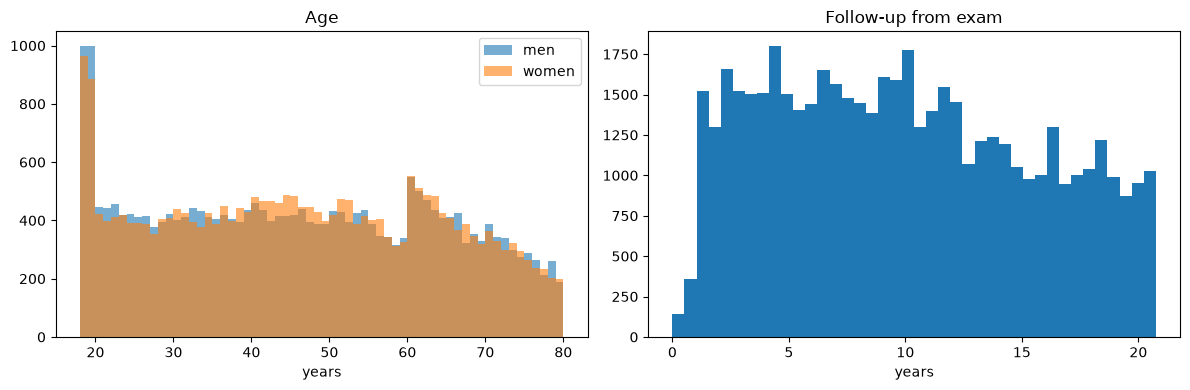

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for sex, label in [(1, "men"), (2, "women")]:
    axes[0].hist(data.loc[data["RIAGENDR"] == sex, "RIDAGEYR"], bins=range(18, 81), alpha=0.6, label=label)
axes[0].set(title="Age", xlabel="years")
axes[0].legend()

axes[1].hist(data["PERMTH_EXM"] / 12, bins=40)
axes[1].set(title="Follow-up from exam", xlabel="years")

plt.tight_layout()

## 1. ¿Qué hay?

Primero el conjunto de todas las columnas, después las candidatas por ciclo (% de personas con dato).

In [6]:
coverage_all = data.notna().mean()
bins = pd.cut(coverage_all, [-0.01, 0, 0.1, 0.5, 0.9, 1], labels=["0%", "<10%", "10-50%", "50-90%", ">90%"])
bins.value_counts().sort_index().rename("columns")

0%        132
<10%      403
10-50%    186
50-90%    156
>90%      116
Name: columns, dtype: int64

In [7]:
coverage = (data.groupby("cycle")[list(CANDIDATES)].apply(lambda g: g.notna().mean()) * 100).T.round(0)
coverage.insert(0, "group", [CANDIDATES[v][0] for v in coverage.index])
coverage.insert(1, "name", [CANDIDATES[v][1] for v in coverage.index])
coverage["all"] = (data[list(CANDIDATES)].notna().mean() * 100).round(0)
coverage

cycle,group,name,1999_2000,2001_2002,2003_2004,2005_2006,2007_2008,2009_2010,2011_2012,2013_2014,2015_2016,2017_2018,all
RIDAGEYR,demographics,age,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
RIAGENDR,demographics,"sex (1 male, 2 female)",100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
LBXWBCSI,routine,leukocytes (10^3/uL),95.0,95.0,96.0,94.0,94.0,95.0,95.0,96.0,95.0,95.0,95.0
LBXRBCSI,routine,erythrocytes (10^6/uL),95.0,95.0,96.0,94.0,94.0,95.0,95.0,96.0,95.0,95.0,95.0
LBXHGB,routine,hemoglobin (g/dL),95.0,95.0,96.0,94.0,94.0,95.0,95.0,96.0,95.0,95.0,95.0
LBXHCT,routine,hematocrit (%),95.0,95.0,96.0,94.0,94.0,95.0,95.0,96.0,95.0,95.0,95.0
LBXMCVSI,routine,MCV (fL),95.0,95.0,96.0,94.0,94.0,95.0,95.0,96.0,95.0,95.0,95.0
LBXMCHSI,routine,MCH (pg),95.0,95.0,96.0,94.0,94.0,95.0,95.0,96.0,95.0,95.0,95.0
LBXMC,routine,MCHC (g/dL),95.0,95.0,96.0,94.0,94.0,95.0,95.0,96.0,95.0,95.0,95.0
LBXRDW,routine,RDW (%),95.0,95.0,96.0,94.0,94.0,95.0,95.0,96.0,95.0,95.0,95.0


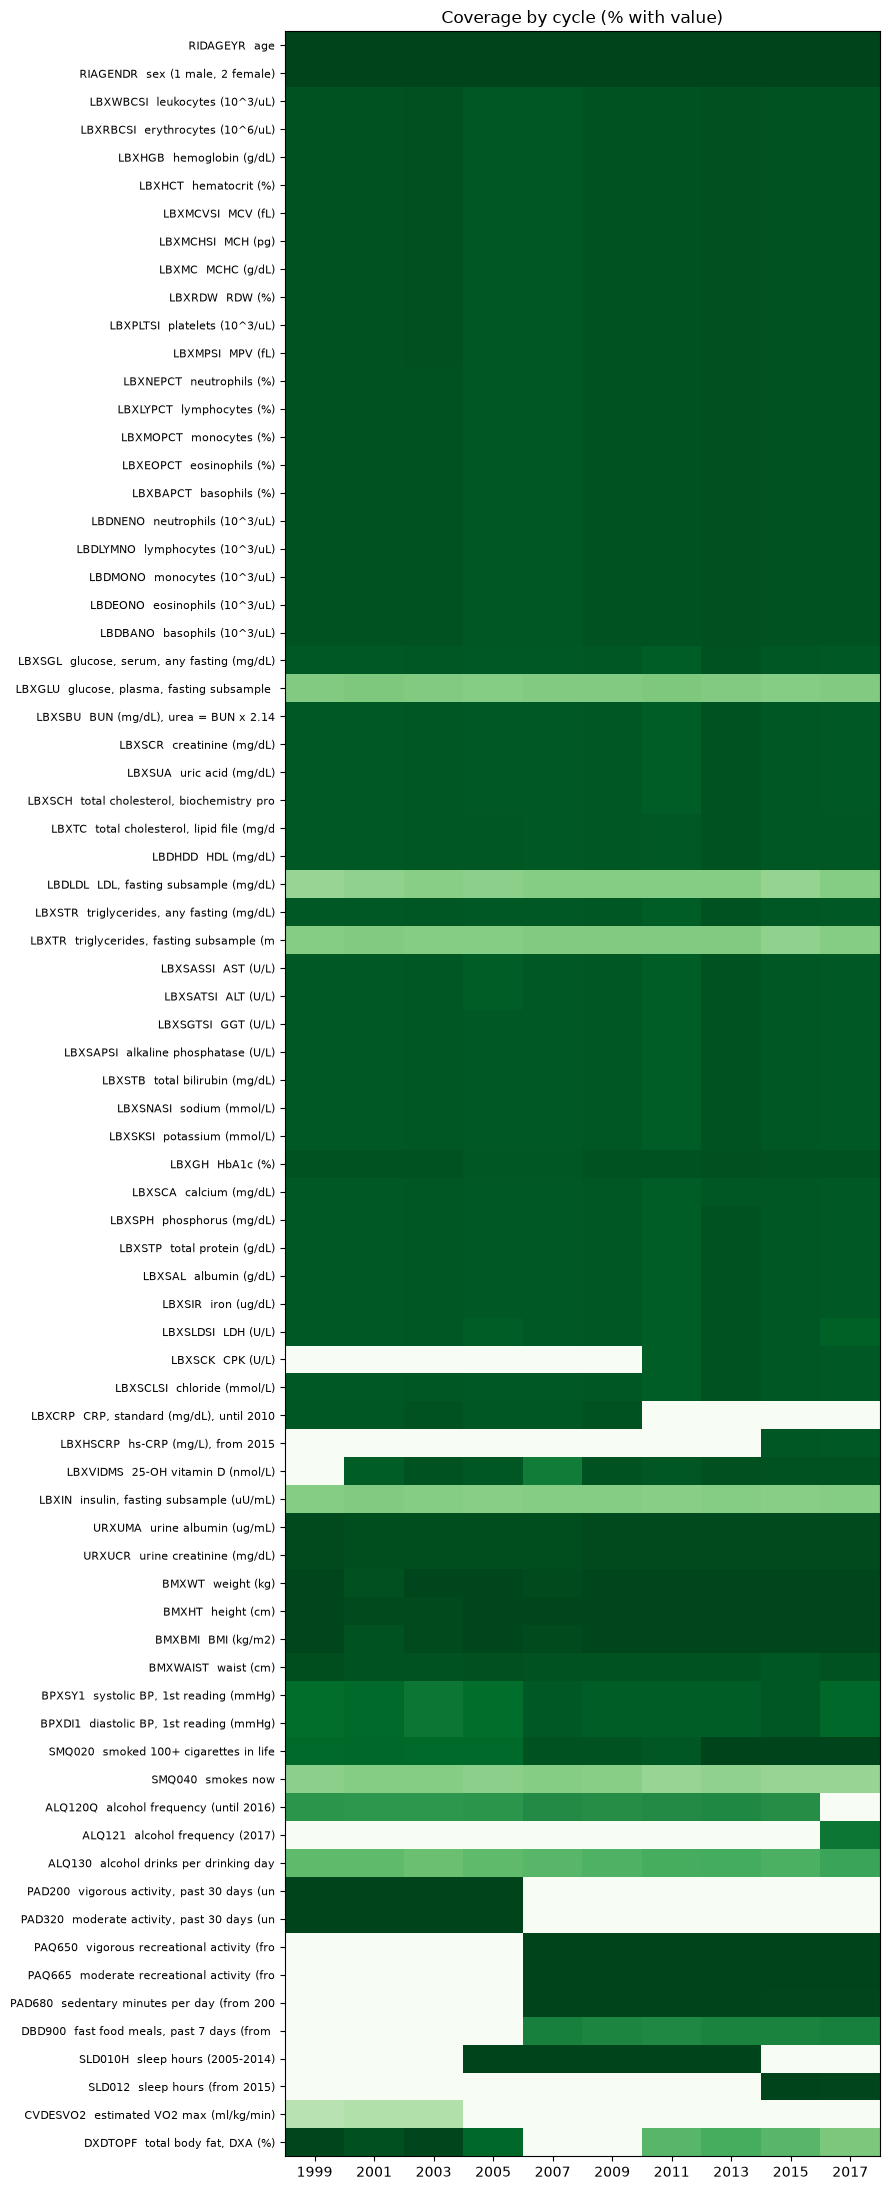

In [8]:
values = coverage.drop(columns=["group", "name", "all"])

fig, ax = plt.subplots(figsize=(9, 22))
ax.imshow(values, aspect="auto", cmap="Greens", vmin=0, vmax=100)
ax.set_xticks(range(values.shape[1]), [c[:4] for c in values.columns])
ax.set_yticks(range(values.shape[0]), [f"{v}  {CANDIDATES[v][1][:35]}" for v in values.index], fontsize=8)
ax.set_title("Coverage by cycle (% with value)")
plt.tight_layout()

## 2. ¿Es fiable y comparable?

- Resumen de cada variable numérica (percentiles 1 y 99 para ver extremos).
- Mediana de cada ciclo dividida entre la mediana global: un salto fuerte en un ciclo apunta a un cambio de método de laboratorio.

In [9]:
summary = data[NUMERIC].describe(percentiles=[0.01, 0.5, 0.99]).T
summary.insert(0, "name", [CANDIDATES[v][1] for v in summary.index])
summary["count"] = summary["count"].astype(int)
summary.round(2)

,name,count,mean,std,min,1%,50%,99%,max
LBXWBCSI,leukocytes (10^3/uL),48406,7.22,2.90,1.40,3.50,6.90,13.50,400.00
LBXRBCSI,erythrocytes (10^6/uL),48407,4.72,0.50,2.28,3.59,4.70,5.90,8.30
LBXHGB,hemoglobin (g/dL),48407,14.20,1.54,5.80,10.10,14.20,17.50,19.90
LBXHCT,hematocrit (%),48407,41.94,4.32,19.70,31.00,42.00,51.30,59.10
LBXMCVSI,MCV (fL),48407,89.09,5.81,35.40,69.31,89.60,101.40,125.30
LBXMCHSI,MCH (pg),48407,30.17,2.37,12.40,22.00,30.40,34.90,60.80
LBXMC,MCHC (g/dL),48422,33.84,0.99,25.10,31.30,33.80,36.10,44.90
LBXRDW,RDW (%),48407,13.13,1.34,9.70,11.40,12.90,18.20,37.80
LBXPLTSI,platelets (10^3/uL),48406,254.53,67.02,11.00,123.00,247.00,449.00,999.90
LBXMPSI,MPV (fL),48406,8.22,0.92,5.00,6.40,8.10,10.80,15.10


In [10]:
medians = data.groupby("cycle")[NUMERIC].median().T
ratio = medians.div(data[NUMERIC].median(), axis=0)

jumps = ratio[(ratio - 1).abs().max(axis=1) > 0.15]
print("Variables with a cycle median more than 15% away from the overall median:")
jumps.round(2)

Variables with a cycle median more than 15% away from the overall median:


cycle,1999_2000,2001_2002,2003_2004,2005_2006,2007_2008,2009_2010,2011_2012,2013_2014,2015_2016,2017_2018
LBXBAPCT,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.17,1.33,1.17
LBDMONO,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.20,1.20,1.00
LBDBANO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,inf,inf
LBXSBU,1.08,1.08,0.92,1.00,1.00,1.00,1.00,1.00,1.08,1.17
LBXSAPSI,1.18,0.99,1.00,1.00,0.99,0.97,0.94,0.93,0.97,1.12
LBXSTB,0.83,1.17,1.17,1.17,1.17,1.17,1.17,1.00,0.83,0.67
LBXSLDSI,1.15,0.98,0.95,0.95,0.99,0.98,0.95,0.93,0.96,1.18
LBXCRP,1.16,1.05,1.05,1.00,1.00,0.95,NaN,NaN,NaN,NaN
LBXIN,1.09,1.03,0.84,0.90,1.00,1.14,1.06,0.93,0.98,1.02
PAD680,NaN,NaN,NaN,NaN,0.80,1.00,1.00,1.40,1.20,1.00


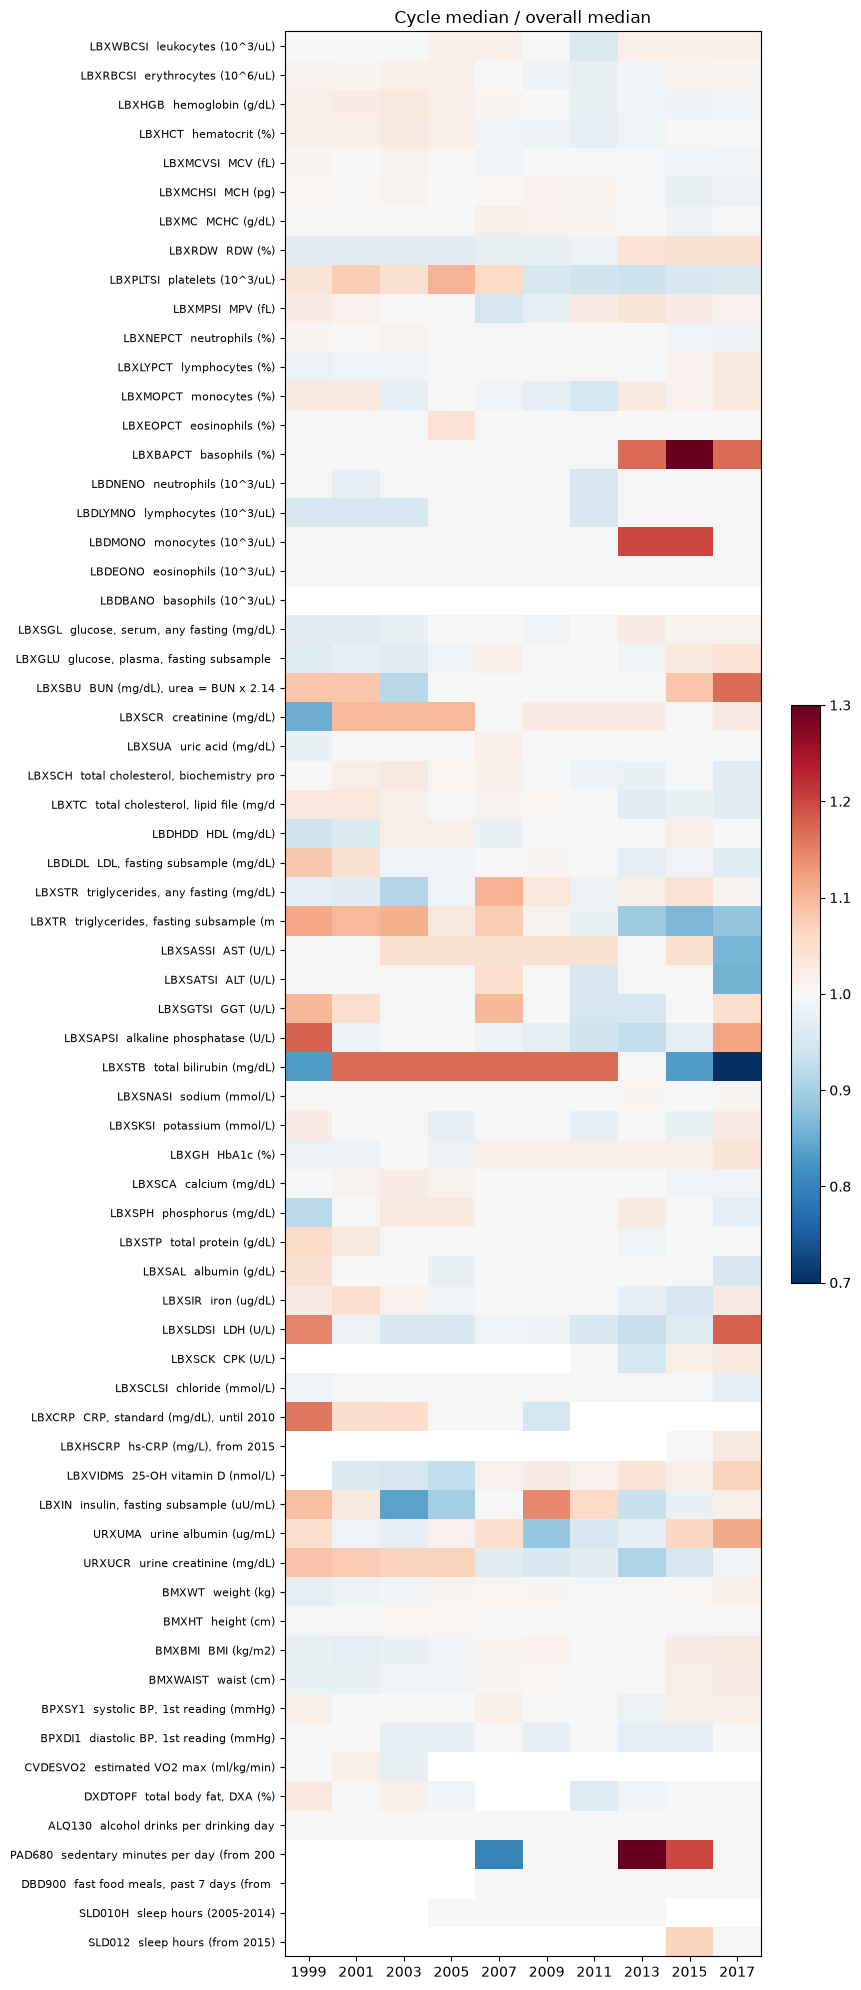

In [11]:
fig, ax = plt.subplots(figsize=(9, 20))
im = ax.imshow(ratio, aspect="auto", cmap="RdBu_r", vmin=0.7, vmax=1.3)
ax.set_xticks(range(ratio.shape[1]), [c[:4] for c in ratio.columns])
ax.set_yticks(range(ratio.shape[0]), [f"{v}  {CANDIDATES[v][1][:35]}" for v in ratio.index], fontsize=8)
ax.set_title("Cycle median / overall median")
fig.colorbar(im, ax=ax, shrink=0.3)
plt.tight_layout()

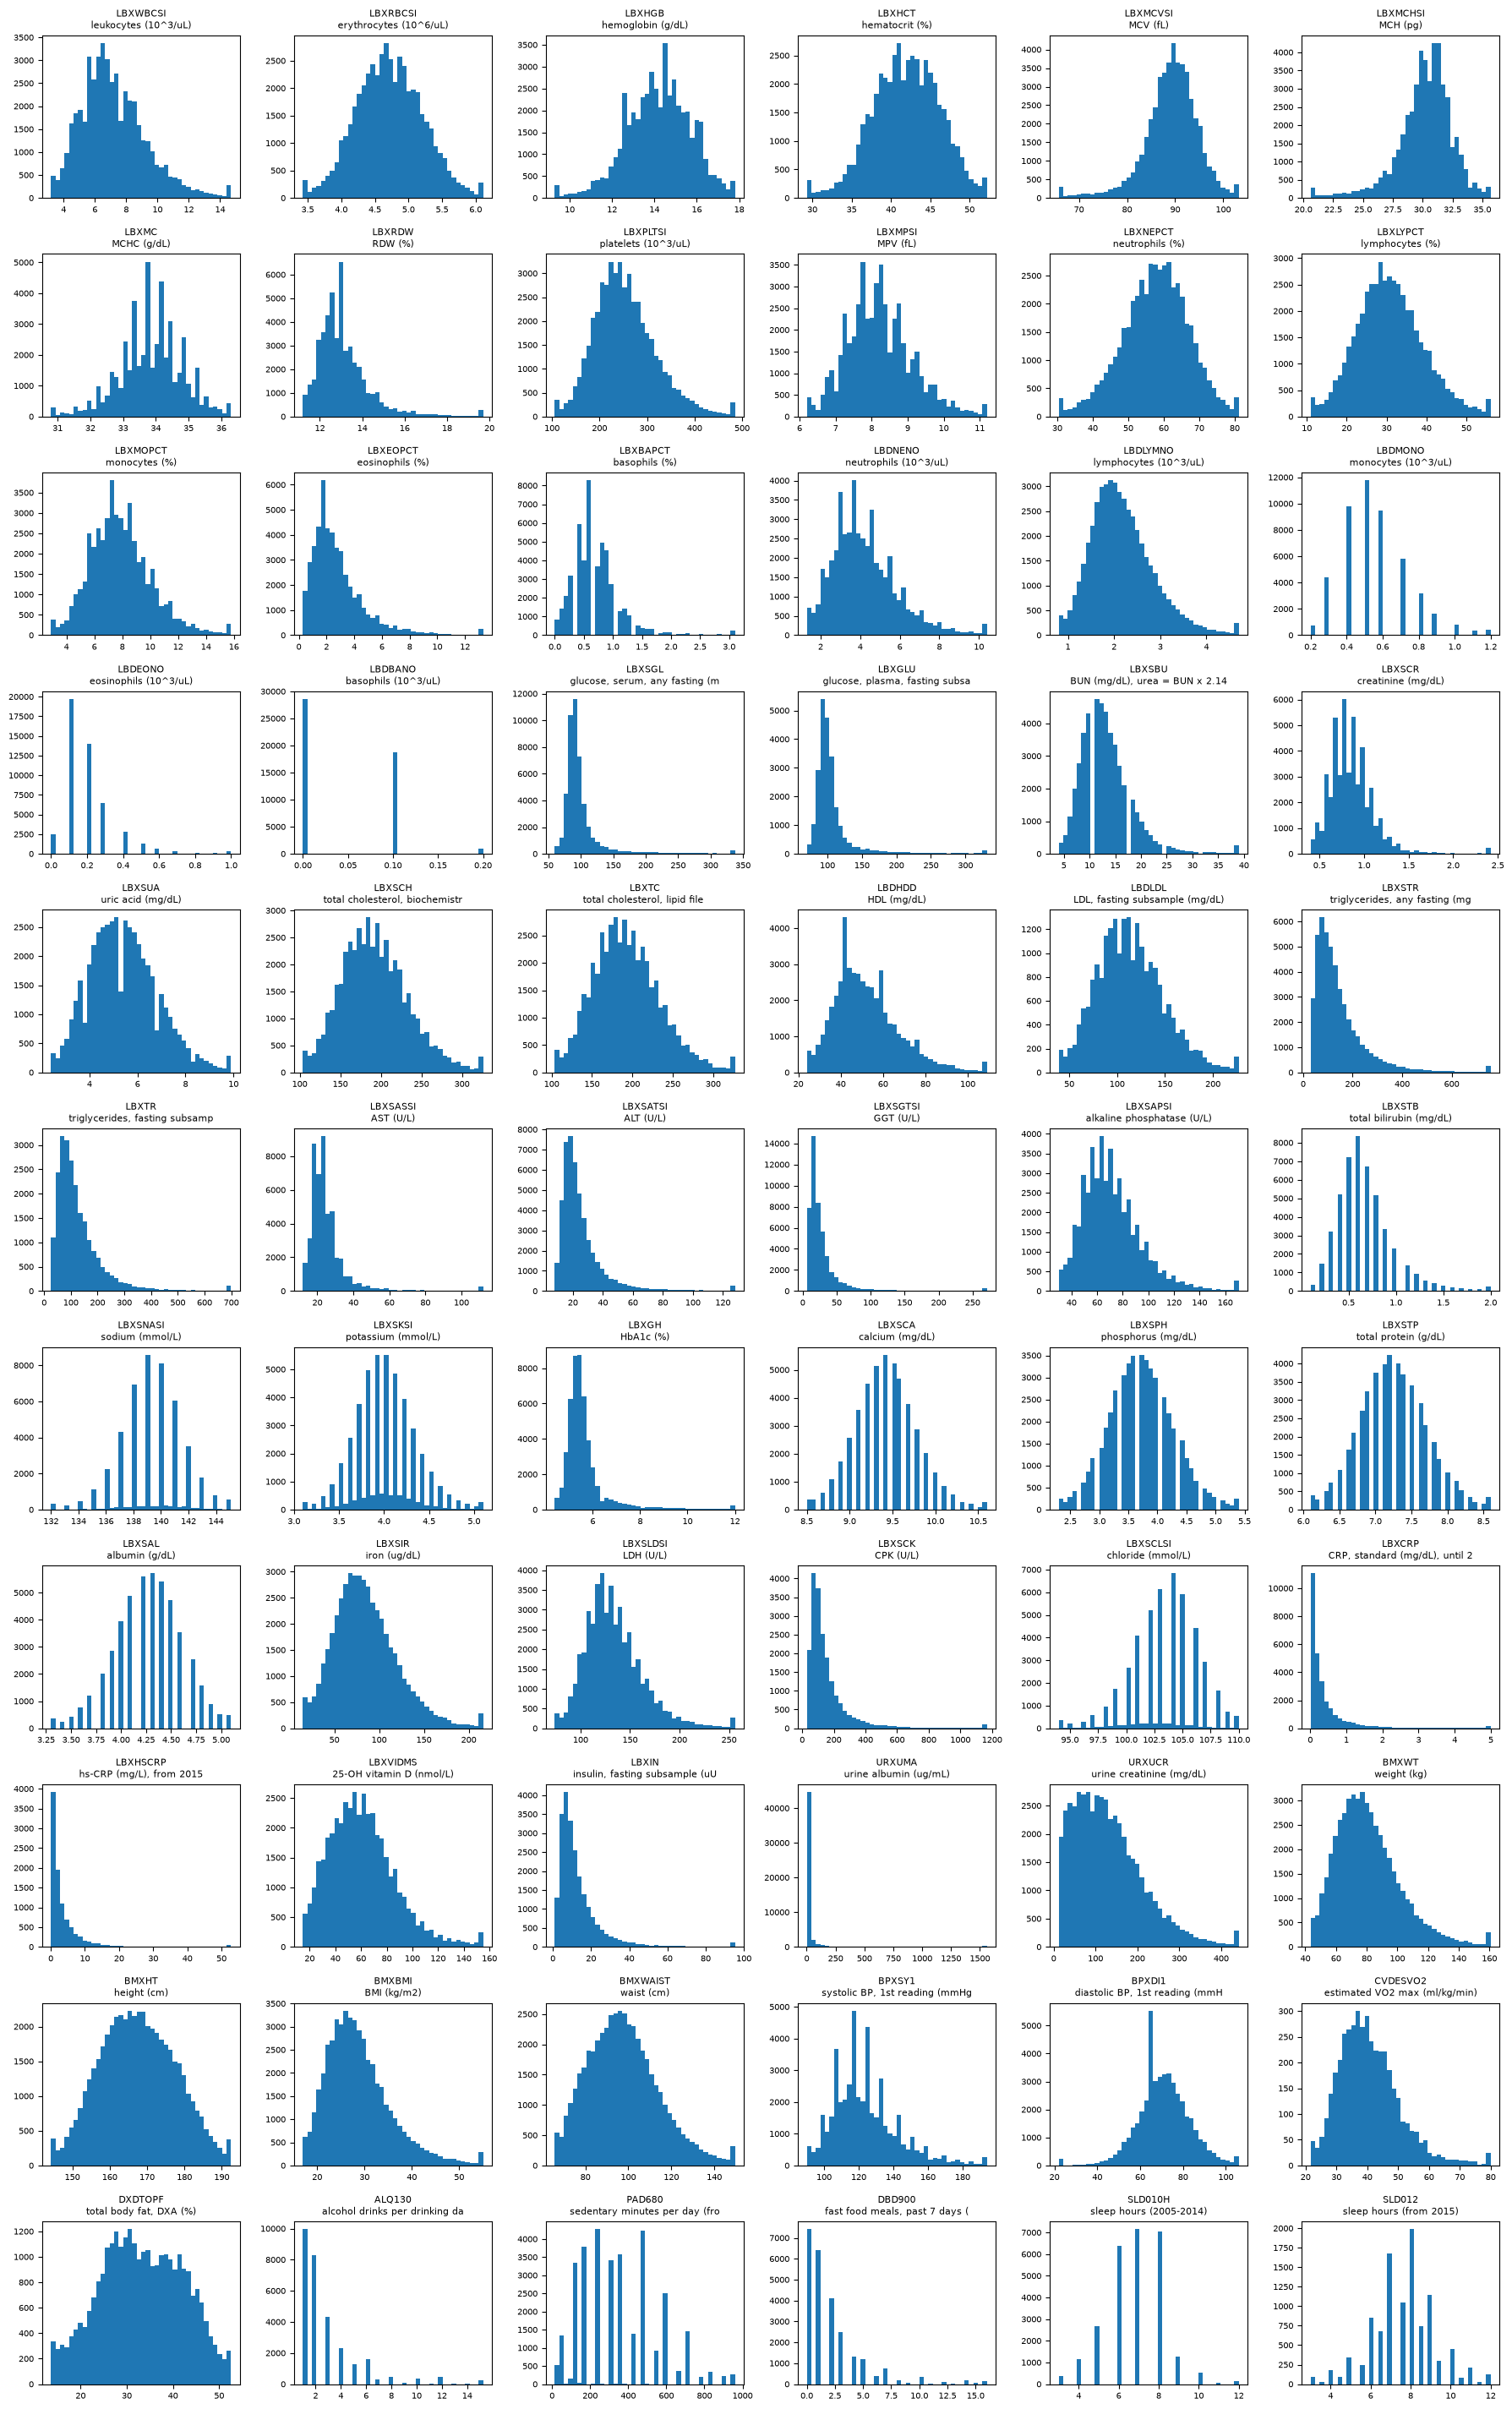

In [12]:
cols = 6
rows = int(np.ceil(len(NUMERIC) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(18, 2.6 * rows))

for ax, var in zip(axes.flat, NUMERIC):
    values = data[var].dropna()
    low, high = values.quantile([0.005, 0.995])
    ax.hist(values.clip(low, high), bins=40)
    ax.set_title(f"{var}\n{CANDIDATES[var][1][:30]}", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes.flat[len(NUMERIC):]:
    ax.axis("off")

plt.tight_layout()

## 3. ¿Aporta algo?

**Correlaciones** (Spearman, robusta a distribuciones asimétricas). Se listan las parejas con |r| ≥ 0,8.

In [13]:
corr = data[NUMERIC].corr(method="spearman", min_periods=500)

pairs = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    .stack()
    .rename("r")
    .reset_index()
    .rename(columns={"level_0": "var_1", "level_1": "var_2"})
)
pairs = pairs[pairs["r"].abs() >= 0.8].sort_values("r", key=abs, ascending=False)
pairs["name_1"] = pairs["var_1"].map(lambda v: CANDIDATES[v][1])
pairs["name_2"] = pairs["var_2"].map(lambda v: CANDIDATES[v][1])
pairs.round(2)

,var_1,var_2,r,name_1,name_2
1325,LBXSCH,LBXTC,0.98,"total cholesterol, biochemistry profile (mg/dL)","total cholesterol, lipid file (mg/dL)"
1479,LBXSTR,LBXTR,0.98,"triglycerides, any fasting (mg/dL)","triglycerides, fasting subsample (mg/dL)"
129,LBXHGB,LBXHCT,0.96,hemoglobin (g/dL),hematocrit (%)
1110,LBXSGL,LBXGLU,0.93,"glucose, serum, any fasting (mg/dL)","glucose, plasma, fasting subsample (mg/dL)"
605,LBXNEPCT,LBXLYPCT,-0.93,neutrophils (%),lymphocytes (%)
14,LBXWBCSI,LBDNENO,0.91,leukocytes (10^3/uL),neutrophils (10^3/uL)
1366,LBXTC,LBDLDL,0.91,"total cholesterol, lipid file (mg/dL)","LDL, fasting subsample (mg/dL)"
2084,BMXBMI,BMXWAIST,0.91,BMI (kg/m2),waist (cm)
254,LBXMCVSI,LBXMCHSI,0.90,MCV (fL),MCH (pg)
1327,LBXSCH,LBDLDL,0.90,"total cholesterol, biochemistry profile (mg/dL)","LDL, fasting subsample (mg/dL)"


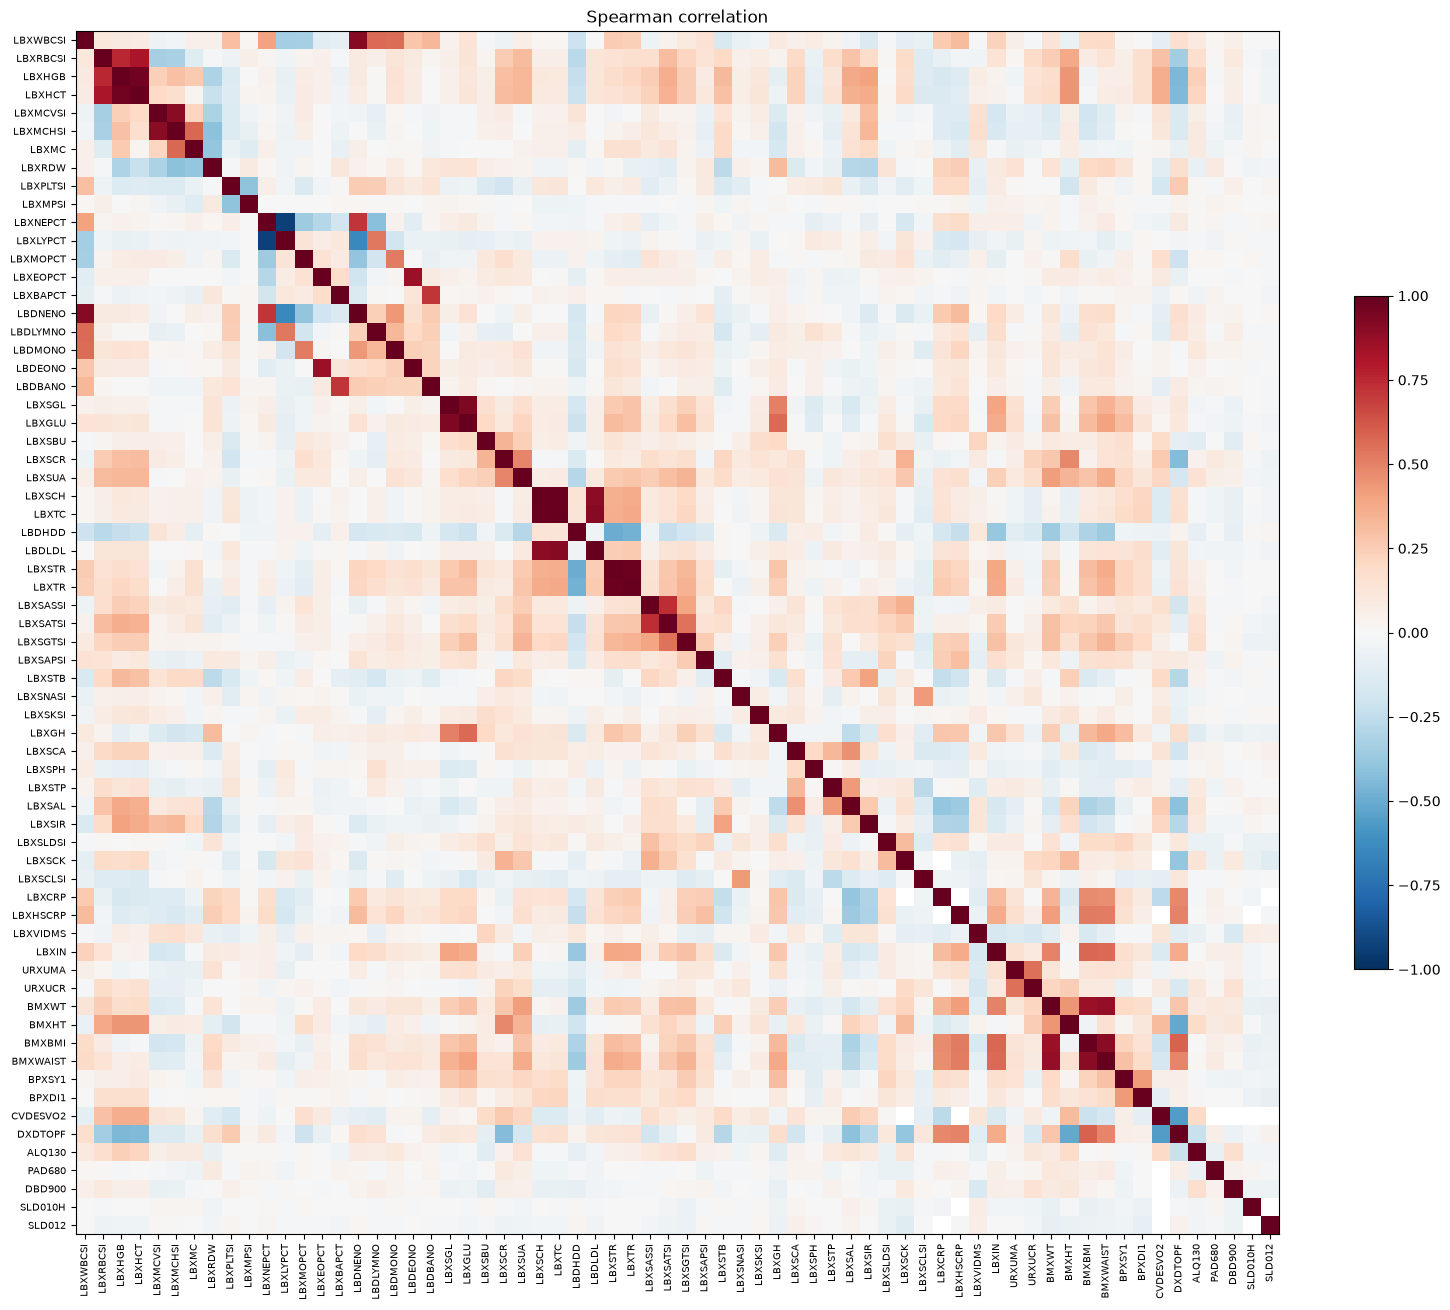

In [14]:
fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=90, fontsize=7)
ax.set_yticks(range(len(NUMERIC)), NUMERIC, fontsize=7)
ax.set_title("Spearman correlation")
fig.colorbar(im, ax=ax, shrink=0.5)
plt.tight_layout()

**Asociación con mortalidad**: un Cox por variable, ajustado por edad y sexo.

- HR por cada desviación estándar de la variable (en logaritmo si es muy asimétrica).
- Orientativo: no detecta relaciones en U (p. ej. sodio, IMC), no usa pesos muestrales y cada variable se mira sola.

In [15]:
def cox_age_sex(data, var):
    """
    Age and sex adjusted Cox model for one variable:
        - Log scale if skewness > 2 and no negative values
        - HR per standard deviation
    """
    df = data[[var, "RIDAGEYR", "RIAGENDR", "PERMTH_EXM", "MORTSTAT"]].dropna()
    df = df[df["PERMTH_EXM"] > 0]
    x = df[var]
    log = x.skew() > 2 and x.min() >= 0
    if log:
        x = np.log1p(x)

    model_data = pd.DataFrame({
        "z": (x - x.mean()) / x.std(),
        "age": df["RIDAGEYR"],
        "female": (df["RIAGENDR"] == 2).astype(int),
        "time": df["PERMTH_EXM"],
        "event": df["MORTSTAT"],
    })
    cox = CoxPHFitter().fit(model_data, duration_col="time", event_col="event")
    row = cox.summary.loc["z"]
    return {
        "name": CANDIDATES[var][1],
        "persons": len(df),
        "deaths": int(df["MORTSTAT"].sum()),
        "log": log,
        "HR_per_SD": row["exp(coef)"],
        "CI_low": row["exp(coef) lower 95%"],
        "CI_high": row["exp(coef) upper 95%"],
        "p": row["p"],
    }


mortality = pd.DataFrame({var: cox_age_sex(data, var) for var in NUMERIC if var != "RIDAGEYR"}).T
mortality = mortality.sort_values("HR_per_SD", key=lambda s: np.log(s.astype(float)).abs(), ascending=False)
mortality.round(3)

,name,persons,deaths,log,HR_per_SD,CI_low,CI_high,p
LBXHSCRP,"hs-CRP (mg/L), from 2015",9693,212,True,1.462969,1.309776,1.63408,0.0
LBXSAL,albumin (g/dL),47690,5299,False,0.699623,0.679731,0.720098,0.0
URXUMA,urine albumin (ug/mL),49801,5485,True,1.37212,1.344809,1.399985,0.0
LBXRDW,RDW (%),48402,5410,True,1.367962,1.340659,1.395821,0.0
LBXVIDMS,25-OH vitamin D (nmol/L),43195,4205,False,0.766178,0.739317,0.794014,0.0
LBXSAPSI,alkaline phosphatase (U/L),47684,5298,True,1.281009,1.247825,1.315076,0.0
LBXSGTSI,GGT (U/L),47683,5299,True,1.278203,1.246575,1.310633,0.0
LBXSCK,CPK (U/L),19737,793,True,0.794625,0.732476,0.862046,0.0
SLD012,sleep hours (from 2015),10301,235,False,1.239582,1.089092,1.410868,0.001145
ALQ130,alcohol drinks per drinking day,29747,2715,True,1.238082,1.18996,1.28815,0.0


## Para decidir

Con estos resultados, la elección de variables se hace en conversación:
- Cobertura mínima aceptable por variable.
- Qué variable se queda en cada pareja muy correlacionada.
- Qué hacer con los saltos entre ciclos.
- Qué preguntas entran en el cuestionario.